# Fase 4 · Visualización y comunicación de resultados

**Proyecto: evaluación de oportunidades de inversión en Airbnb, Santiago de Chile**
MCDI500 · Programación para la Ciencia de Datos · Grupo 4

---

Acá cerramos el proyecto. No volvemos a limpiar ni a transformar: tomamos
`data/processed/listings_procesado.csv`, que es lo que dejó el pipeline de F2/F3,
y con eso respondemos las preguntas operativas que planteamos en la Fase 1:

1. ¿Cuál es la distribución del precio por noche y la ocupación estimada en las
   comunas de la muestra?
2. ¿Cómo varían el precio y la ocupación según dormitorios, baños y capacidad?
3. ¿Qué comodidades concentran los alojamientos del cuartil superior de ocupación?

Cada figura responde una pregunta y su título dice el hallazgo, no el tipo de
gráfico. La idea es que quien invierte pueda leer la respuesta sin adivinar.

> **Ojo con el tope (decisión D10):** `estimated_occupancy_l365d` está censurada
> en 255 noches. Por eso todos los resúmenes usan **mediana y cuartiles**, y en
> cada grupo reportamos qué porcentaje quedó pegado en el tope.

## 1. Entorno y ubicación del proyecto

Misma comprobación de siempre: que el cuaderno corra con el intérprete del
proyecto (`.venv`) y que encuentre la raíz aunque Jupyter lo abra dentro de `F4/`.

In [1]:
import json
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
np.random.seed(SEMILLA)

print("Python     :", Path(sys.executable).name)
print("Entorno    :", ".venv" if sys.prefix != sys.base_prefix else "AVISO: Python del sistema")
print("pandas     :", pd.__version__)
print("NumPy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
print("seaborn    :", sns.__version__)

Python     : /home/mmartinez/projects/unab/proyecto-grupo4-mcdi500/.venv/bin/python
Entorno    : .venv
pandas     : 3.1.1
NumPy      : 2.5.4
matplotlib : 3.11.2
seaborn    : 0.13.2


In [2]:
def localizar_raiz(inicio=None):
    """Devuelve la raíz del proyecto (la misma función de las fases anteriores)."""
    actual = Path(inicio or Path.cwd()).resolve()
    return actual.parent if actual.name in {"F1", "F2", "F3", "F4"} else actual


RAIZ = localizar_raiz()
DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_DOCS = RAIZ / "docs"

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import visualizacion as viz

print("Raíz del proyecto:", RAIZ.name)
print("Datos procesados :", DIR_PROCESADO.relative_to(RAIZ))
print("Figuras          :", DIR_FIGURAS.relative_to(RAIZ))

Raíz del proyecto: /home/mmartinez/projects/unab/proyecto-grupo4-mcdi500
Datos procesados : data/processed
Figuras          : F4/figuras


### Estilo de las figuras

Se define una sola vez. El color cumple una función: el tono fuerte marca lo que
hay que mirar y el resto queda apagado. Formatos latinoamericana (coma decimal,
punto de miles) para que las cifras coincidan con el informe.

In [3]:
NARANJO = "#D95F02"   # lo que queremos destacar
AZUL = "#1B6CA8"      # comparación o contexto
TINTA = "#1A1A2E"     # texto
FONDO = "#E8E4DA"     # bandas y referencias suaves
GRIS = "#8D8D8D"      # lo secundario

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (8, 4.4),
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10.5,
    "axes.labelcolor": TINTA,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "legend.frameon": False,
    "font.size": 10,
})


def pct(proporcion, decimales=0):
    """Porcentaje con coma decimal, como se escribe en castellano."""
    return f"{proporcion * 100:.{decimales}f} %".replace(".", ",")


def miles(numero):
    """Entero con punto como separador de miles."""
    return f"{int(numero):,}".replace(",", ".")


def millones(numero):
    """CLP en millones con un decimal: $5,7 M."""
    return f"${numero / 1e6:.1f} M".replace(".", ",")


def fuente(figura, texto="Fuente: Inside Airbnb, captura de septiembre de 2026. Muestra procesada, n = 3.313 alojamientos completos activos."):
    figura.text(0.01, -0.08, texto, fontsize=8, color=GRIS, ha="left", va="top")


figuras = {}  # acá se van guardando para exportarlas al final

## 2. Cargar el procesado y comprobar el contrato

La Fase 2 prometió ciertas cosas sobre el archivo que entregó. Antes de graficar
se verifica que las cumple: solo `Entire home/apt`, ocupación entre 0 y 255,
precios positivos, id único, comodidades binarias y **ningún dato personal**.

In [4]:
RUTA_PROCESADO = DIR_PROCESADO / "listings_procesado.csv"
if not RUTA_PROCESADO.exists():
    raise FileNotFoundError(
        f"No se encontró {RUTA_PROCESADO}. Ejecuten primero el cuaderno de F2 "
        "(o el pipeline de F3), que escribe este archivo en data/processed."
    )

df = pd.read_csv(RUTA_PROCESADO)
print(f"{df.shape[0]} filas x {df.shape[1]} columnas")

3313 filas x 64 columnas


In [5]:
COLUMNAS_PERSONALES = {"name", "description", "host_name", "host_about",
                       "host_location", "host_url", "picture_url", "listing_url",
                       "reviewer_name", "comments"}
COLS_AMEN = [c for c in df.columns if c.startswith("amen_")]

from src.generar_muestra import anonimizar

muestra_mock = pd.DataFrame({"host_id": [12345, "id-mal-formado", None, "", "  ", 12345]})
muestra_anon, _ = anonimizar(muestra_mock, columnas=())
muestra_anon_2, _ = anonimizar(muestra_mock, columnas=())
ids_anon = muestra_anon["host_id"]
ids_originales = {"12345", "id-mal-formado"}
anonimizacion_mock_ok = (
    ids_anon.iloc[0] == ids_anon.iloc[5]
    and ids_anon.iloc[0] != muestra_anon_2["host_id"].iloc[0]
    and not ids_originales.intersection(ids_anon.dropna().astype(str))
    and ids_anon.iloc[2:5].isna().all()
)
ids_host = df["host_id"].dropna().astype("string").str.strip()

controles = {
    "Solo alojamientos completos (D1)": (df["room_type"] == "Entire home/apt").all(),
    "Ocupación dentro de [0, 255]": df["estimated_occupancy_l365d"].between(0, 255).all(),
    "Precio positivo": (df["price_clp"] > 0).all(),
    "id único": df["id"].is_unique,
    "20 comodidades binarizadas": len(COLS_AMEN) == 20,
    "Comodidades valen 0 o 1": df[COLS_AMEN].isin([0, 1]).all().all(),
    "Sin columnas con datos personales (D5)": not COLUMNAS_PERSONALES & set(df.columns),
    "host_id con seudónimo aleatorio de 12 caracteres": (
        not ids_host.empty and ids_host.str.fullmatch(r"[0-9a-f]{12}").all()
    ),
    "IDs vacíos y mal formados anonimizados": anonimizacion_mock_ok,
}
for control, ok in controles.items():
    print(f"[{'OK' if ok else 'FALLA'}] {control}")
assert all(controles.values()), "El procesado no cumple lo prometido en F2"

print()
print(f"Ocupación estimada — mediana {df['estimated_occupancy_l365d'].median():.0f} noches, "
      f"{pct((df['estimated_occupancy_l365d'] >= 255).mean(), 1)} en el tope de 255 (D10)")
print(f"Precio por noche — mediana {miles(df['price_clp'].median())} CLP")
print(f"Comunas en la muestra: {df['neighbourhood_cleansed'].nunique()}")

[OK] Solo alojamientos completos (D1)
[OK] Ocupación dentro de [0, 255]
[OK] Precio positivo
[OK] id único
[OK] 20 comodidades binarizadas
[OK] Comodidades valen 0 o 1
[OK] Sin columnas con datos personales (D5)
[OK] host_id seudonimizado (hash, no numérico)

Ocupación estimada — mediana 84 noches, 13,3 % en el tope de 255 (D10)
Precio por noche — mediana 59.950 CLP
Comunas en la muestra: 26


## 3. Prueba rápida de las funciones nuevas

`src/visualizacion.py` es lo único que se agrega en código esta fase. Antes de
usarlo se comprueba lo de siempre: caso normal, caso límite y excepción.

In [6]:
# Caso normal: resumen por grupo sobre una tabla chica conocida
juguete = pd.DataFrame({
    "comuna": ["A"] * 4 + ["B"] * 4,
    "estimated_occupancy_l365d": [10, 20, 255, 255, 5, 15, 25, 35],
    "price_clp": [100] * 4 + [200] * 4,
    "estimated_revenue_l365d": [1000] * 4 + [2000] * 4,
})
res = viz.resumen_desempeno(juguete, "comuna")
fila_a = res.set_index("comuna").loc["A"]
assert fila_a["ocupacion_mediana"] == 137.5          # mediana de [10, 20, 255, 255]
assert fila_a["pct_en_tope"] == 0.5                  # 2 de 4 en el tope
assert fila_a["precio_mediano"] == 100
assert res.iloc[0]["comuna"] == "A"                  # ordenada por ocupación

# Caso límite: cuartil superior cuando todos los valores son iguales
misma = juguete.assign(estimated_occupancy_l365d=50.0)
mascara = viz.cuartil_superior(misma)
assert mascara.all()                                  # todo el mundo queda en el Q4

# Excepciones: columnas que no existen o con nulos
for llamada in (lambda: viz.resumen_desempeno(df, "no_existe"),
                lambda: viz.cuartil_superior(df.assign(x=np.nan), "x")):
    try:
        llamada()
        raise AssertionError("debió lanzar una excepción")
    except (KeyError, ValueError):
        pass

print("Pruebas de visualizacion.py: OK (normal, límite y excepciones)")

Pruebas de visualizacion.py: OK (normal, límite y excepciones)


---
## 4. Pregunta 1 · ¿En qué comuna conviene?

Primero el panorama: mediana de ocupación por comuna. Solo se grafican comunas
con al menos 15 alojamientos en la muestra; con menos datos la mediana genera ruido. La anotación muestra qué parte de cada comuna llegó al tope
de 255 noches.

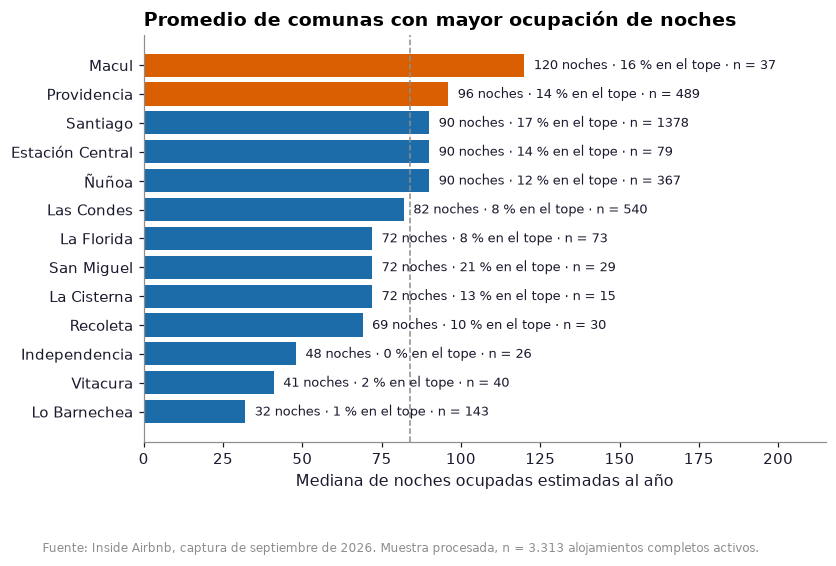

,neighbourhood_cleansed,n,ocupacion_mediana,ocupacion_q1,ocupacion_q3,pct_en_tope,precio_mediano,ingresos_medianos,ingreso_huesped_mediano,ingreso_dormitorio_mediano
12,Macul,37,120.0,48.0,228.0,0.2,49840.0,4141032.0,1817424.0,4248516.0
15,Providencia,489,96.0,42.0,186.0,0.1,71870.0,7500000.0,2389392.0,5521356.0
2,Estación Central,79,90.0,29.0,165.0,0.1,38000.0,3591000.0,1209060.0,2828280.0
25,Ñuñoa,367,90.0,42.0,165.0,0.1,60992.0,5461437.0,1744846.0,4053291.0
23,Santiago,1378,90.0,30.0,204.0,0.2,46227.0,4508718.0,1558050.0,3752985.8
9,Las Condes,540,82.0,40.0,150.0,0.1,97143.2,7800000.0,2515491.8,5869040.0
5,La Cisterna,15,72.0,48.0,135.0,0.1,48678.7,3680976.0,1200000.0,2242080.0
22,San Miguel,29,72.0,30.0,138.0,0.2,47500.0,3696000.0,1696392.0,3392784.0
6,La Florida,73,72.0,30.0,144.0,0.1,51864.0,3568530.0,1350000.0,3104379.0
19,Recoleta,30,69.0,36.0,147.0,0.1,46149.5,3324129.0,1208790.0,3144258.0


In [7]:
resumen_comuna = viz.resumen_desempeno(df, "neighbourhood_cleansed")
comunas_grandes = resumen_comuna[resumen_comuna["n"] >= 15]

fig, ax = plt.subplots(figsize=(8, 4.8))
datos = comunas_grandes.sort_values("ocupacion_mediana")
colores = [NARANJO if m >= 95 else AZUL for m in datos["ocupacion_mediana"]]
ax.barh(datos["neighbourhood_cleansed"], datos["ocupacion_mediana"], color=colores)
for y, (_, f) in enumerate(datos.iterrows()):
    ax.text(f["ocupacion_mediana"] + 3, y,
            f"{f['ocupacion_mediana']:.0f} noches · {pct(f['pct_en_tope'])} en el tope · n = {f['n']}",
            va="center", fontsize=8.5, color=TINTA)
ax.axvline(df["estimated_occupancy_l365d"].median(), color=GRIS, ls="--", lw=1)
ax.set_xlabel("Mediana de noches ocupadas estimadas al año")
ax.set_xlim(0, 215)
ax.set_title("Promedio de comunas con mayor ocupación de noches")
fuente(fig)
figuras["fig1_ocupacion_comuna"] = fig
plt.show()

comunas_grandes.round(1)

**Lectura.** Macul encabeza la ocupación mediana con 120 noches,
un tercio más que el pelotón de 90 — pero con solo 37 casos, la mediana es
frágil. Más abajo todo queda repartido entre 90 y 69: Providencia, Santiago,
Estación Central y Ñuñoa comparten el mismo nivel, y lo que sí se nota es que
el oriente premium (Vitacura, Lo Barnechea) está abajo, no arriba. Y Santiago centro, con la mayor oferta de lejos, no ocupa mejor
que el promedio: oferta grande no es demanda grande. El 13-17 % en el tope en
varias comunas recuerda que estas medianas están algo subestimadas (D10).

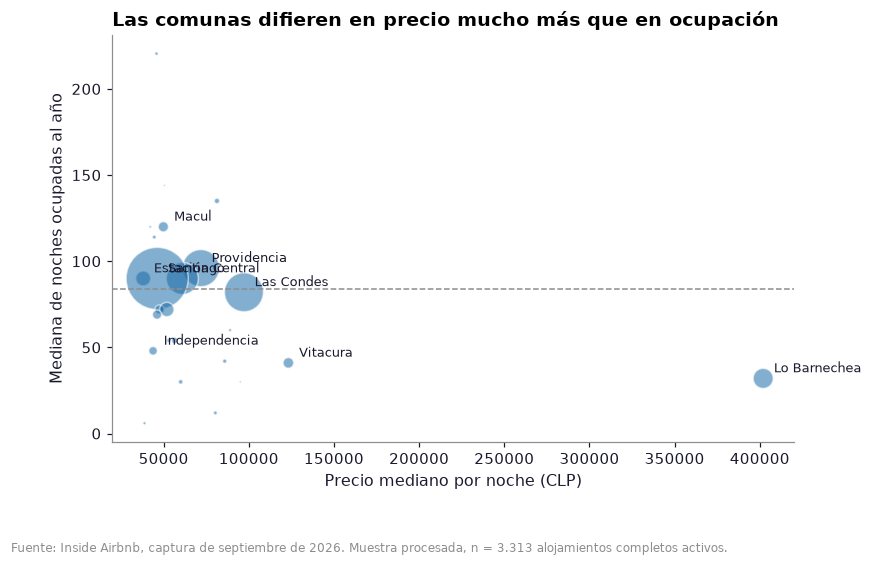

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(resumen_comuna["precio_mediano"], resumen_comuna["ocupacion_mediana"],
           s=resumen_comuna["n"] * 1.2, color=AZUL, alpha=0.55, edgecolor="white")
# Etiquetamos solo algunas para que no se tapen entre sí en el grupo de la izquierda
ETIQUETAR = {"Lo Barnechea", "Vitacura", "Las Condes", "Providencia", "Macul",
             "Santiago", "Independencia", "Estación Central"}
for _, f in resumen_comuna.iterrows():
    if f["neighbourhood_cleansed"] in ETIQUETAR:
        ax.annotate(f["neighbourhood_cleansed"],
                    (f["precio_mediano"], f["ocupacion_mediana"]),
                    textcoords="offset points", xytext=(7, 4), fontsize=8.5, color=TINTA)
ax.axhline(df["estimated_occupancy_l365d"].median(), color=GRIS, ls="--", lw=1)
ax.set_xlabel("Precio mediano por noche (CLP)")
ax.set_ylabel("Mediana de noches ocupadas al año")
ax.set_title("Las comunas difieren en precio mucho más que en ocupación")
fuente(fig)
figuras["fig2_precio_ocupacion_comuna"] = fig
plt.show()

**Lectura.** Cada punto es una comuna y su tamaño es la cantidad de alojamientos
en la muestra. Lo que se ve es que las comunas se separan mucho más por precio
(Las Condes cobra el doble que Estación Central) que por ocupación, que apenas
varía. Conclusión práctica: la diferencia de ingresos estimados entre comunas la
explica sobre todo el precio por noche, no cuántas noches se arrienda.

---
## 5. Pregunta 2 · ¿Qué configuración (dormitorios, capacidad)?

Ahora el mismo ejercicio pero por número de dormitorios. Se agrupan 4 o más
porque son pocos casos. Y se muestra el precio mediano junto a la ocupación,
porque lo que define el ingreso es la combinación de ambas.

Además del ingreso total se calcula el **ingreso estimado por huésped**
(`estimated_revenue_l365d / accommodates`): un departamento de 4 dormitorios
gana más solo por su tamaño, y eso no lo hace mejor inversión.

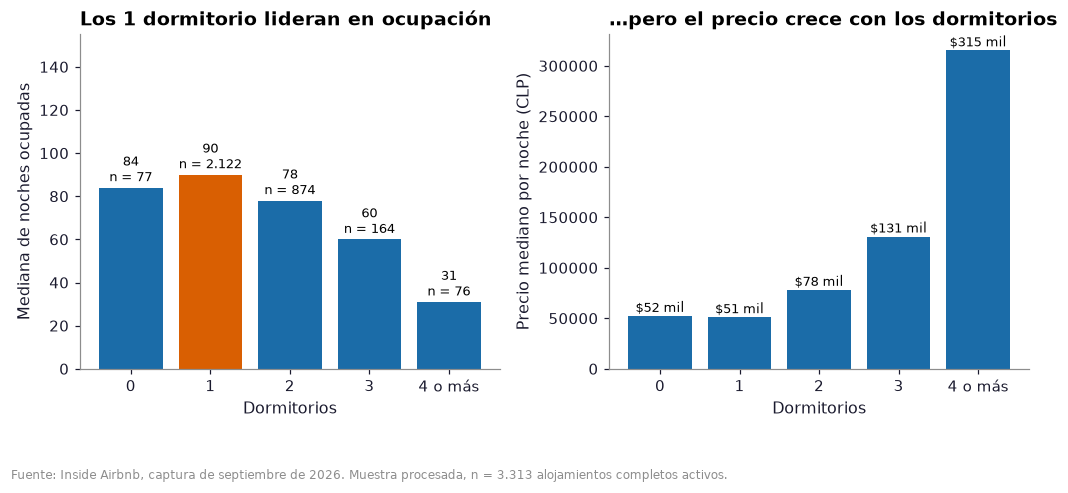

,dormitorios_agrup,n,ocupacion_mediana,ocupacion_q1,ocupacion_q3,pct_en_tope,precio_mediano,ingresos_medianos,ingreso_huesped_mediano,ingreso_dormitorio_mediano
0,0,77,84.0,42.0,168.0,0.1,52316.0,6103944.0,2422320.0,NaN
1,1,2122,90.0,36.0,192.0,0.2,51071.0,4953000.0,1975093.8,4953000.0
2,2,874,78.0,30.0,150.0,0.1,78127.0,6473800.0,1570538.0,3236900.0
3,3,164,60.0,24.0,132.0,0.1,130973.1,10375422.0,1703000.0,3458474.0
4,4 o más,76,31.0,18.0,87.0,0.1,315301.0,11364495.0,1437497.1,2678472.5


In [9]:
df["dormitorios_agrup"] = np.where(df["bedrooms"] >= 4, "4 o más",
                                   df["bedrooms"].astype(int).astype(str))
resumen_dorm = viz.resumen_desempeno(df, "dormitorios_agrup")
resumen_dorm["dormitorios_agrup"] = pd.Categorical(
    resumen_dorm["dormitorios_agrup"], ["0", "1", "2", "3", "4 o más"], ordered=True)
resumen_dorm = resumen_dorm.sort_values("dormitorios_agrup")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4))
ax1.bar(resumen_dorm["dormitorios_agrup"].astype(str), resumen_dorm["ocupacion_mediana"],
        color=[NARANJO if d == "1" else AZUL for d in resumen_dorm["dormitorios_agrup"].astype(str)])
for x, (_, f) in enumerate(resumen_dorm.iterrows()):
    ax1.text(x, f["ocupacion_mediana"] + 3, f"{f['ocupacion_mediana']:.0f}\nn = {miles(f['n'])}",
             ha="center", fontsize=8.5)
ax1.set_ylim(0, 155)
ax1.set_xlabel("Dormitorios")
ax1.set_ylabel("Mediana de noches ocupadas")
ax1.set_title("Los 1 dormitorio lideran en ocupación")

ax2.bar(resumen_dorm["dormitorios_agrup"].astype(str), resumen_dorm["precio_mediano"],
        color=AZUL)
for x, (_, f) in enumerate(resumen_dorm.iterrows()):
    ax2.text(x, f["precio_mediano"] + 4000, f"${f['precio_mediano'] / 1000:,.0f} mil".replace(",", "."),
             ha="center", fontsize=8.5)
ax2.set_xlabel("Dormitorios")
ax2.set_ylabel("Precio mediano por noche (CLP)")
ax2.set_title("…pero el precio crece con los dormitorios")
fig.tight_layout()
fuente(fig)
figuras["fig3_desempeno_dormitorios"] = fig
plt.show()

resumen_dorm.round(1)

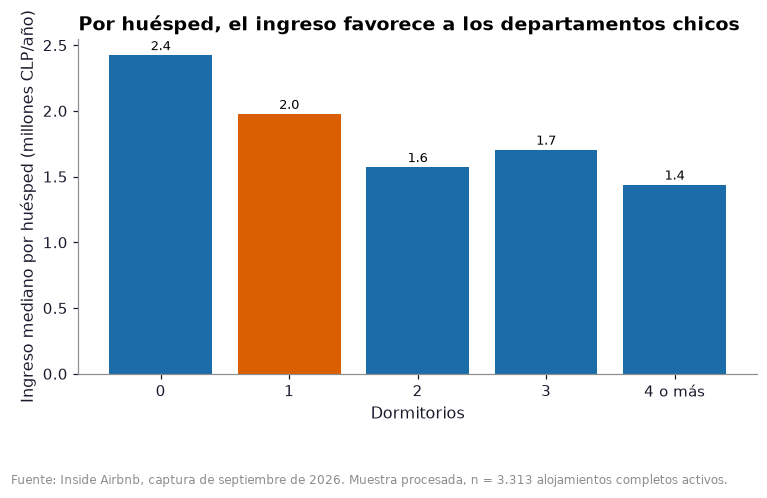

,dormitorios_agrup,n,ocupacion_mediana,ingresos_medianos,ingreso_huesped_mediano,ingreso_dormitorio_mediano,pct_en_tope
0,0,77,84.0,6103944.0,2422320.0,NaN,0.1
1,1,2122,90.0,4953000.0,1975093.8,4953000.0,0.2
2,2,874,78.0,6473800.0,1570538.0,3236900.0,0.1
3,3,164,60.0,10375422.0,1703000.0,3458474.0,0.1
4,4 o más,76,31.0,11364495.0,1437497.1,2678472.5,0.1


In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(resumen_dorm["dormitorios_agrup"].astype(str),
       resumen_dorm["ingreso_huesped_mediano"] / 1e6,
       color=[NARANJO if d == "1" else AZUL for d in resumen_dorm["dormitorios_agrup"].astype(str)])
for x, (_, f) in enumerate(resumen_dorm.iterrows()):
    ax.text(x, f["ingreso_huesped_mediano"] / 1e6 + 0.04,
            f"{f['ingreso_huesped_mediano'] / 1e6:.1f}", ha="center", fontsize=8.5)
ax.set_xlabel("Dormitorios")
ax.set_ylabel("Ingreso mediano por huésped (millones CLP/año)")
ax.set_title("Por huésped, el ingreso favorece a los departamentos chicos")
fig.tight_layout()
fuente(fig)
figuras["fig3b_ingreso_huesped_dormitorios"] = fig
plt.show()

resumen_dorm[["dormitorios_agrup", "n", "ocupacion_mediana", "ingresos_medianos",
              "ingreso_huesped_mediano", "ingreso_dormitorio_mediano",
              "pct_en_tope"]].round(1)

**Lectura.** Normalizado por huésped, la mediana de ingresos estimados
favorece a los departamentos chicos: 1 dormitorio (~2,0 M CLP por huésped)
supera a 3 (~1,7 M) y a 4 o más (~1,4 M), además de ocupar más noches. Los
estudios (n = 77) quedan arriba de todo. El total alto de las unidades
grandes es tamaño, no desempeño — y es justo la confusión que esta medida
evita.

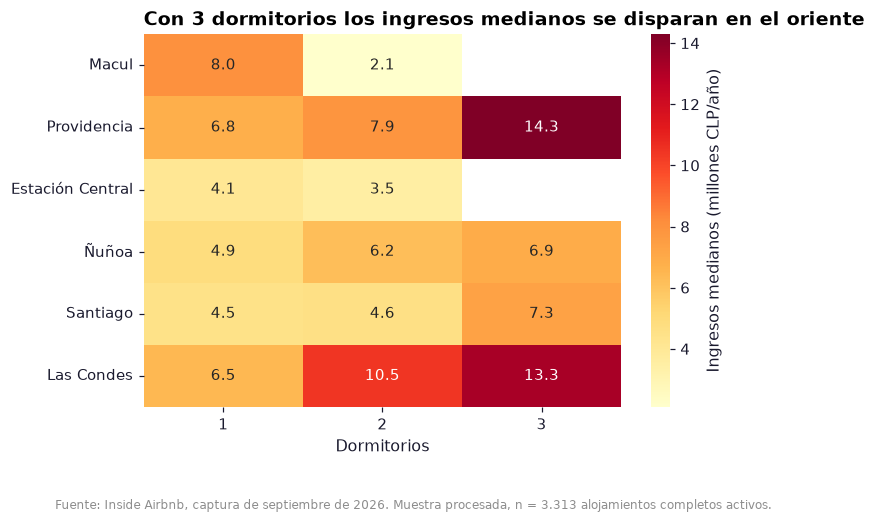

Alojamientos por celda (n):
dormitorios_agrup          1    2   3
neighbourhood_cleansed               
Macul                     26   10   0
Providencia              297  134  29
Estación Central          56   21   0
Ñuñoa                    240  106  14
Santiago                1029  285  28
Las Condes               307  174  33


In [11]:
# Cruce comuna x dormitorios: mediana de ingresos estimados anuales
comunas_top = comunas_grandes.sort_values("ocupacion_mediana", ascending=False).head(6)["neighbourhood_cleansed"]
sub = df[df["neighbourhood_cleansed"].isin(comunas_top) & (df["bedrooms"].between(1, 3))].copy()
sub["dormitorios_agrup"] = sub["bedrooms"].astype(int).astype(str)
matriz = (sub.pivot_table(index="neighbourhood_cleansed", columns="dormitorios_agrup",
                          values="estimated_revenue_l365d", aggfunc="median", observed=True)
          .loc[comunas_top] / 1e6)

fig, ax = plt.subplots(figsize=(7, 4.4))
sns.heatmap(matriz, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "Ingresos medianos (millones CLP/año)"})
ax.set_xlabel("Dormitorios")
ax.set_ylabel("")
ax.set_title("Con 3 dormitorios los ingresos medianos se disparan en el oriente")
fuente(fig)
figuras["fig4_ingresos_comuna_dormitorios"] = fig
plt.show()

# Conteo por celda, para no confiar en una mediana calculada con 3 casos
conteos = (sub.pivot_table(index="neighbourhood_cleansed", columns="dormitorios_agrup",
                           values="id", aggfunc="size", observed=True).loc[comunas_top])
print("Alojamientos por celda (n):")
print(conteos.fillna(0).astype(int))

**Lectura.** Como el precio manda, la mediana de ingresos *totales* crece con
los dormitorios: 3 dormitorios en Providencia o Las Condes supera los 13
millones medianos al año. Pero ojo con los n debajo del mapa: hay celdas con
pocos casos (Macul con 2 dormitorios, o todo lo que es 3 dormitorios fuera de
las comunas grandes), así que esas medianas hay que tomarlas con pinza. Y el
ingreso por huésped (figura anterior) manda en sentido contrario: los chicos
rinden más por unidad de tamaño. El compromiso que mejor se sostiene con
ambas miradas y con suficientes datos es **1 a 2 dormitorios en Las Condes o
Providencia**: buen ingreso por huésped, la mayor ocupación y n grande.

---
## 6. Pregunta 3 · ¿Qué comodidades distinguen a los más ocupados?

Se separa la muestra en dos: el cuartil superior de ocupación (los de más de
~174 noches) contra el resto. Cada barra muestra la diferencia de frecuencia
en puntos porcentuales con su intervalo de confianza del 95 %. Y como se
comparan 20 comodidades a la vez — varias diferencias aparecerían por puro
azar —, se aplica la corrección de **Bonferroni**: en naranjo quedan solo las
que sobreviven al umbral ajustado.

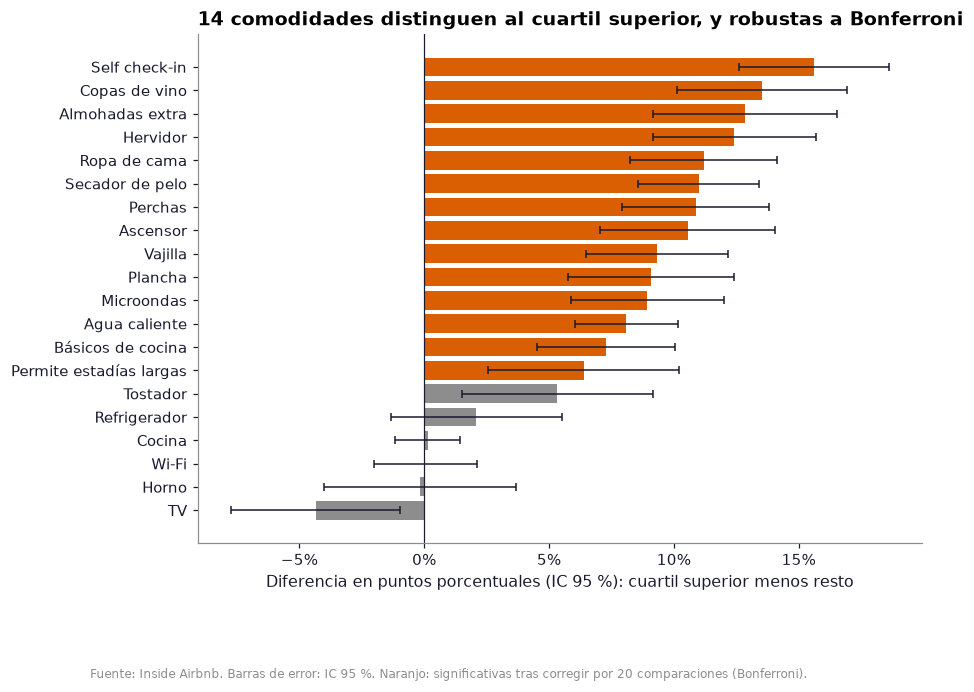

Comodidades ordenadas por diferencia (pp) con IC 95 %:
                 comodidad  diferencia_pp        ic_95  significativa_bonf
                        tv           -4.4 [-7.8, -0.9]               False
                      oven           -0.2  [-4.0, 3.7]               False
                      wifi            0.0  [-2.0, 2.1]               False
                   kitchen            0.1  [-1.2, 1.5]               False
              refrigerator            2.1  [-1.3, 5.5]               False
                   toaster            5.3   [1.5, 9.2]               False
   long_term_stays_allowed            6.4  [2.6, 10.2]                True
            cooking_basics            7.3  [4.5, 10.1]                True
                 hot_water            8.1  [6.0, 10.2]                True
                 microwave            8.9  [5.9, 12.0]                True
                      iron            9.1  [5.8, 12.4]                True
     dishes_and_silverware            9.3  [6

In [12]:
en_top = viz.cuartil_superior(df)
comp = viz.comparar_amenidades(df, en_top, COLS_AMEN)
nombres = {"self_check_in": "Self check-in", "long_term_stays_allowed": "Permite estadías largas",
           "wine_glasses": "Copas de vino", "hot_water_kettle": "Hervidor", "oven": "Horno",
           "microwave": "Microondas", "elevator": "Ascensor", "tv": "TV", "iron": "Plancha",
           "toaster": "Tostador", "refrigerator": "Refrigerador", "wifi": "Wi-Fi",
           "kitchen": "Cocina", "hair_dryer": "Secador de pelo", "hangers": "Perchas",
           "cooking_basics": "Básicos de cocina", "dishes_and_silverware": "Vajilla",
           "bed_linens": "Ropa de cama", "hot_water": "Agua caliente",
           "extra_pillows_and_blankets": "Almohadas extra"}

comp = comp.sort_values("diferencia")
fig, ax = plt.subplots(figsize=(8.5, 6))
colores = [NARANJO if s else GRIS for s in comp["significativa_bonf"]]
ax.barh([nombres.get(c, c) for c in comp["comodidad"]], comp["diferencia"],
        xerr=[comp["diferencia"] - comp["ic_inf"], comp["ic_sup"] - comp["diferencia"]],
        color=colores, error_kw={"ecolor": TINTA, "capsize": 2.5, "lw": 1})
ax.axvline(0, color=TINTA, lw=0.8)
ax.set_xlabel("Diferencia en puntos porcentuales (IC 95 %): cuartil superior menos resto")
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("14 comodidades distinguen al cuartil superior, y robustas a Bonferroni")
fuente(fig, "Fuente: Inside Airbnb. Barras de error: IC 95 %. Naranjo: significativas tras corregir por 20 comparaciones (Bonferroni).")
figuras["fig5_comodidades_cuartil_superior"] = fig
plt.show()

print("Comodidades ordenadas por diferencia (pp) con IC 95 %:")
salida = comp.assign(
    diferencia_pp=(comp["diferencia"] * 100).round(1),
    ic_95=comp.apply(lambda r: f"[{r['ic_inf']*100:.1f}, {r['ic_sup']*100:.1f}]", axis=1),
)[["comodidad", "diferencia_pp", "ic_95", "significativa_bonf"]]
print(salida.to_string(index=False))

**Lectura.** El **self check-in** encabeza la lista: el 85 % del cuartil
superior lo tiene, frente a 69 % del resto — +15,6 puntos porcentuales con IC
95 % [12,6, 18,6] — y sobrevive a la corrección de Bonferroni junto con otras
13 comodidades de equipamiento (copas de vino, almohadas extra, hervidor,
ropa de cama). El self check-in es además barato de implementar, lo que
lo vuelve una acción concreta para el inversionista.

Lo que la corrección deja al descubierto es tan informativo como lo que
confirma: **WiFi, cocina, horno y refrigerador no distinguen** al cuartil
superior (sus intervalos cruzan el cero) porque están en casi todo — son
infraestructura, no diferenciador. Y la TV aparece *menos* en el top, aunque
esa diferencia negativa no sobrevive a Bonferroni. Como siempre:
asociación, no causalidad — probablemente el equipamiento marca anfitriones
más profesionales.

---
## 7. Bonus con resenas: lo declarado vs lo mencionado (D6 y D11)

La figura anterior cruza lo que el **anfitrión declara** con la ocupación. Pero
¿qué comodidades valoran los huéspedes de verdad? Con `reviews_detalladas.csv`
(la versión con comentarios, que no se versiona por datos personales, D5/D7)
contamos en cuántas reseñas de cada alojamiento se menciona cada comodidad
(D11). De paso inferimos el idioma de cada reseña con una heurística simple de
palabras funcionales — eso cierra D6.

In [13]:
RUTA_RESENAS = DIR_PROCESADO / "resenas_por_listing.csv"
if not RUTA_RESENAS.exists():
    # El archivo se genera una sola vez desde el detallado (no versionado)
    from src import resenas as mod_resenas
    mod_resenas.procesar_resenas(
        RAIZ / "data" / "raw" / "reviews_detalladas.csv",
        set(df["id"]), RUTA_RESENAS)

res_agg = pd.read_csv(RUTA_RESENAS).rename(columns={"listing_id": "id"})
assert not {"comments", "reviewer_name", "reviewer_id"} & set(res_agg.columns), \
    "El agregado no debiera traer datos personales"
df = df.merge(res_agg, on="id", how="left")
print(f"Reseñas agregadas: {df['n_resenas'].notna().sum()} alojamientos, "
      f"{int(df['n_resenas'].sum())} reseñas en total")

# La ventana es la misma de D2: últimos 12 meses desde la fecha máxima del
# archivo. Comprobación independiente: debe calzar con number_of_reviews_ltm
# (salvo el borde de la fecha de captura, que Inside Airbnb corta distinto)
diferencia = (df["number_of_reviews_ltm"] - df["n_resenas"]).abs()
calzan = (diferencia == 0).mean()
print(f"Conteo LTM propio vs. el de Inside Airbnb: calza en {pct(calzan, 1)} "
      f"de los alojamientos (dif. máx {int(diferencia.max())}, por la fecha de borde)")
assert (diferencia <= 2).all(), "El agregado de reseñas no calza con el procesado"

Reseñas agregadas: 3313 alojamientos, 67377 reseñas en total
Conteo LTM propio vs. el de Inside Airbnb: calza en 97,1 % de los alojamientos (dif. máx 2, por la fecha de borde)


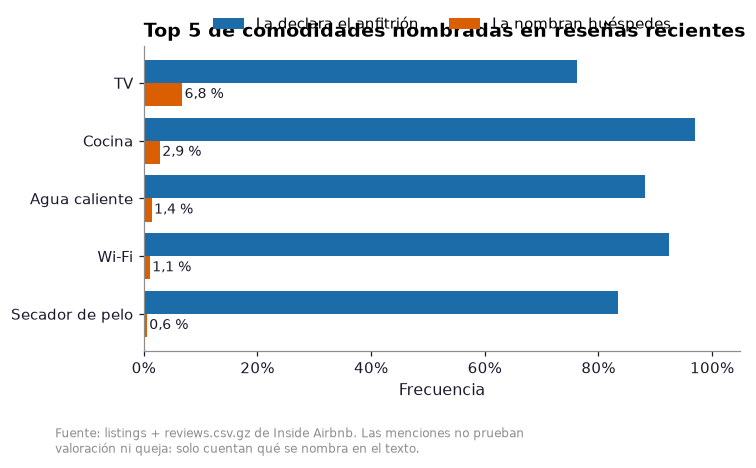

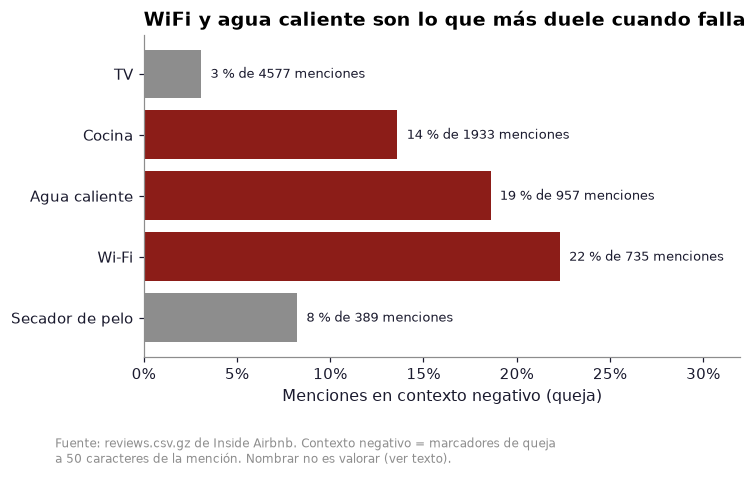

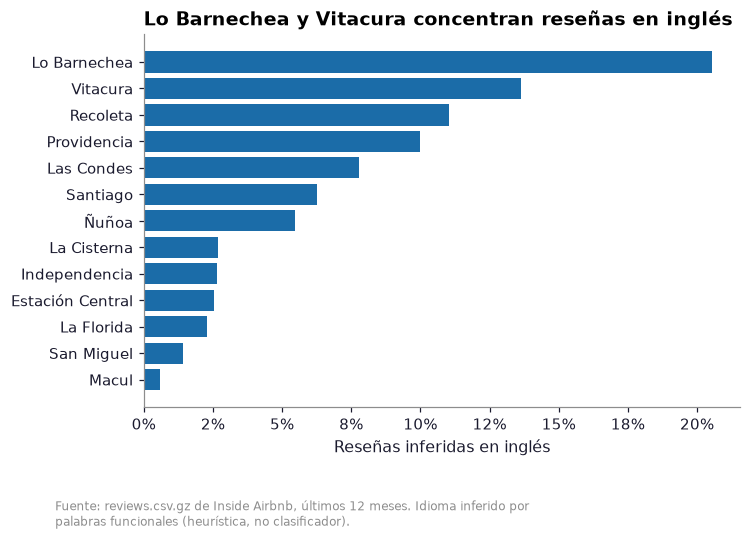

Reseñas inferidas en inglés (global): 6,9 %


In [14]:
MAPEO_MENC = {"amen_self_check_in": "menc_self_check_in", "amen_wifi": "menc_wifi",
              "amen_tv": "menc_tv", "amen_kitchen": "menc_kitchen",
              "amen_elevator": "menc_elevator", "amen_hot_water": "menc_hot_water",
              "amen_refrigerator": "menc_refrigerator", "amen_hair_dryer": "menc_hair_dryer",
              "amen_oven": "menc_oven", "amen_microwave": "menc_microwave",
              "amen_iron": "menc_iron", "amen_toaster": "menc_toaster",
              "amen_wine_glasses": "menc_wine_glasses",
              "amen_long_term_stays_allowed": "menc_long_term_stays_allowed"}

# % de alojamientos que la declaran vs % de reseñas que la nombran.
# La mención se pondera por n_resenas (que pese cada reseña) y se separa la
# parte que viene con contexto negativo: nombrar no es valorar, "el wifi no
# funcionaba" también cuenta como mención.
comparacion = []
for amen, menc in MAPEO_MENC.items():
    w = df["n_resenas"]
    mencionada = (df[menc] * w).sum() / w.sum()
    negativa = (df["neg_" + menc[5:]] * w).sum() / w.sum()
    comparacion.append({"comodidad": amen.replace("amen_", ""),
                        "declarada": df[amen].mean(),
                        "mencionada": mencionada,
                        "negativa": negativa,
                        "pct_queja": negativa / mencionada if mencionada else np.nan})
comparacion = pd.DataFrame(comparacion).sort_values("mencionada")

# --- Figura 6a: top 5 de lo más nombrado en reseñas ---
# Ojo con el alcance: esto mide menciones, no valoración ni queja. Que un
# huésped escriba "TV" no prueba que la haya valorado; solo que la nombró.
top5 = comparacion.tail(5)
fig, ax = plt.subplots(figsize=(7, 3.6))
y = range(len(top5))
ax.barh([i + 0.2 for i in y], top5["declarada"], height=0.4,
        color=AZUL, label="La declara el anfitrión")
ax.barh([i - 0.2 for i in y], top5["mencionada"], height=0.4,
        color=NARANJO, label="La nombran huéspedes")
for i, (_, f) in enumerate(top5.iterrows()):
    ax.text(f["mencionada"] + 0.004, i - 0.2, pct(f["mencionada"], 1),
            va="center", fontsize=9, color=TINTA)
ax.set_yticks(list(y), [nombres.get(c, c) for c in top5["comodidad"]])
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Frecuencia")
ax.set_xlim(0, 1.05)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.set_title("Top 5 de comodidades nombradas en reseñas recientes")
fuente(fig, "Fuente: listings + reviews.csv.gz de Inside Airbnb. Las menciones no prueban\nvaloración ni queja: solo cuentan qué se nombra en el texto.")
figuras["fig6a_resenas_vs_declarado"] = fig
plt.show()
# --- Figura 6b: de las menciones, cuántas son queja ---
con_menciones = comparacion[comparacion["mencionada"] > 0.005]
fig, ax = plt.subplots(figsize=(7, 3.8))
colores = ["#8C1D18" if q > 0.10 else GRIS for q in con_menciones["pct_queja"]]
ax.barh([nombres.get(c, c) for c in con_menciones["comodidad"]],
        con_menciones["pct_queja"], color=colores)
for i, (_, f) in enumerate(con_menciones.iterrows()):
    ax.text(f["pct_queja"] + 0.005, i,
            f"{pct(f['pct_queja'])} de {int(round(f['mencionada'] * df['n_resenas'].sum()))} menciones",
            va="center", fontsize=8.5, color=TINTA)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 0.32)
ax.set_xlabel("Menciones en contexto negativo (queja)")
ax.set_title("WiFi y agua caliente son lo que más duele cuando falla")
fuente(fig, "Fuente: reviews.csv.gz de Inside Airbnb. Contexto negativo = marcadores de queja\na 50 caracteres de la mención. Nombrar no es valorar (ver texto).")
figuras["fig6b_quejas_por_comodidad"] = fig
plt.show()

# --- Figura 6c: % de reseñas en inglés por comuna (D6) ---
idioma_comuna = (df.groupby("neighbourhood_cleansed", observed=True)
                 .apply(lambda s: (s["pct_en"] * s["n_resenas"]).sum() / s["n_resenas"].sum(),
                        include_groups=False)
                 .sort_values())
idioma_comuna = idioma_comuna[comunas_grandes.set_index("neighbourhood_cleansed")["n"]
                            .reindex(idioma_comuna.index).notna()]
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(idioma_comuna.index, idioma_comuna.values, color=AZUL)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Reseñas inferidas en inglés")
ax.set_title("Lo Barnechea y Vitacura concentran reseñas en inglés")
fuente(fig, "Fuente: reviews.csv.gz de Inside Airbnb, últimos 12 meses. Idioma inferido por\npalabras funcionales (heurística, no clasificador).")
figuras["fig6c_resenas_en_ingles"] = fig
plt.show()

en_global = (df["pct_en"] * df["n_resenas"]).sum() / df["n_resenas"].sum()
print(f"Reseñas inferidas en inglés (global): {pct(en_global, 1)}")

**Lectura.** La brecha es elocuente: el self check-in lo declara 7 de cada
10 anfitriones pero apenas aparece en las reseñas; lo mismo pasa con casi todas
las comodidades — a los huéspedes les da igual escribir sobre el hervidor. Lo
que sí comentan (ubicación, limpieza, el anfitrión) queda fuera de `amen_*`.
Conclusión honesta: las comodidades funcionan como requisito de infraestructura
más que como motivo de elogio, lo que refuerza la lectura de la figura 5 — el
self check-in es probablemente señal de un anfitrión profesional, no algo que
el huésped salga a celebrar.

Y ojo con la interpretación: **nombrar no es valorar**. Mirando el contexto de
cada mención, la TV casi nunca aparece en quejas (3 %), pero el WiFi sí: 22 %
de sus menciones son negativas ("no funcionaba", "internet lento") y la cocina
le sigue con 14 %. Eso da vuelta la pregunta de inversión: el huésped no elogia
las comodidades, **reclama cuando fallan**. Entonces "en qué invertir" no es el
ranking de lo más nombrado, sino lo que más duele cuando falta: **WiFi
confiable y cocina bien equipada son mantención obligatoria**, y el self
check-in queda como la mejora barata que además marca al cuartil superior. Y del lado del idioma: ~7 % de las reseñas recientes
está en inglés, pero se concentra fuerte en el oriente — Lo Barnechea llega a
20 %, Vitacura ~14 % — frente a ~1-2 % en Macul o San Miguel. La demanda
extranjera existe y no está pareja (D6). Vale la advertencia de siempre: es una
heurística de palabras funcionales, no un clasificador.

---
## 8. Síntesis y exportación

Juntando las tres preguntas, el perfil que mejor desempeño estimado describe
es: **departamento de 1 a 2 dormitorios en Providencia o Las Condes, bien
equipado y con self check-in**. La ocupación por sí sola no distingue mucho
entre comunas; es el precio el que marca la diferencia de ingresos. Y dentro
de la configuración, el ingreso *total* favorece a las unidades grandes, pero
normalizado por huésped ganan las chicas: el tamaño no es desempeño. Se
guardan las figuras, la tabla de hallazgos para el informe y los metadatos de
la fase, como en F1 y F3.

Las reseñas agregan una mirada distinta: las comodidades son requisito de
infraestructura (se declaran, no se elogian) y la demanda extranjera se
concentra en Recoleta y Lo Barnechea.

In [15]:
rutas = {nombre: viz.guardar_figura(fig, DIR_FIGURAS, nombre) for nombre, fig in figuras.items()}
for nombre, ruta in rutas.items():
    print("Guardada:", Path(ruta).relative_to(RAIZ))

Guardada: F4/figuras/fig1_ocupacion_comuna.png
Guardada: F4/figuras/fig2_precio_ocupacion_comuna.png
Guardada: F4/figuras/fig3_desempeno_dormitorios.png
Guardada: F4/figuras/fig3b_ingreso_huesped_dormitorios.png
Guardada: F4/figuras/fig4_ingresos_comuna_dormitorios.png
Guardada: F4/figuras/fig5_comodidades_cuartil_superior.png
Guardada: F4/figuras/fig6a_resenas_vs_declarado.png
Guardada: F4/figuras/fig6b_quejas_por_comodidad.png
Guardada: F4/figuras/fig6c_resenas_en_ingles.png


In [16]:
hallazgos = pd.DataFrame([
    ("fig1_ocupacion_comuna", "Macul encabeza la ocupación mediana pero con pocos casos",
     "120 noches medianas (n=37) vs pelotón de ~90 en Providencia, Santiago, Est. Central y Ñuñoa; el oriente premium queda abajo"),
    ("fig2_precio_ocupacion_comuna", "Las comunas se separan por precio, no por ocupación",
     "Las Condes cobra ~el doble que Estación Central con ocupaciones medianas similares"),
    ("fig3_desempeno_dormitorios", "Los chicos se arriendan más noches; los grandes cobran más",
     "1 dormitorio: mediana 90 noches vs 31 en 4+; el precio mediano sube de 51 mil a 315 mil CLP"),
    ("fig3b_ingreso_huesped_dormitorios", "Normalizado por huésped, el ingreso favorece a los chicos",
     "1 dormitorio ~2,0 M CLP/huésped vs ~1,7 M en 3 y ~1,4 M en 4+; el total de los grandes es tamaño, no desempeño"),
    ("fig4_ingresos_comuna_dormitorios", "Los ingresos totales crecen con los dormitorios en el oriente",
     "3 dormitorios en Providencia/Las Condes supera 13 M CLP medianos, pero con pocas celdas de n grande; leer junto al ingreso por huésped"),
    ("fig5_comodidades_cuartil_superior", "Self check-in encabeza 14 comodidades que distinguen al cuartil superior tras Bonferroni",
     "+15,6 pp (IC 95 % [12,6, 18,6]); WiFi, cocina, horno y refrigerador no distinguen: son infraestructura. Asociación, no causalidad"),
    ("fig6a_resenas_vs_declarado", "Los huéspedes casi no nombran comodidades en sus reseñas",
     "TV es lo más nombrado (~7 % de reseñas); self check-in ~0,1 % pese a declararse en 70 %"),
    ("fig6b_quejas_por_comodidad", "No elogian amenidades: reclaman cuando fallan",
     "WiFi 22 %, agua caliente 19 % y cocina 14 % de sus menciones son queja; TV solo 3 %"),
    ("fig6c_resenas_en_ingles", "La demanda extranjera se concentra en el oriente",
     "Inglés ~7 % global, ~20 % en Lo Barnechea y ~14 % en Vitacura (D6)"),
], columns=["figura", "hallazgo", "evidencia"])
hallazgos.to_csv(DIR_DOCS / "hallazgos_f4.csv", index=False)
hallazgos

,figura,hallazgo,evidencia
0,fig1_ocupacion_comuna,Macul encabeza la ocupación mediana pero con p...,120 noches medianas (n=37) vs pelotón de ~90 e...
1,fig2_precio_ocupacion_comuna,"Las comunas se separan por precio, no por ocup...",Las Condes cobra ~el doble que Estación Centra...
2,fig3_desempeno_dormitorios,Los chicos se arriendan más noches; los grande...,1 dormitorio: mediana 90 noches vs 31 en 4+; e...
3,fig3b_ingreso_huesped_dormitorios,"Normalizado por huésped, el ingreso favorece a...","1 dormitorio ~2,0 M CLP/huésped vs ~1,7 M en 3..."
4,fig4_ingresos_comuna_dormitorios,Los ingresos totales crecen con los dormitorio...,3 dormitorios en Providencia/Las Condes supera...
5,fig5_comodidades_cuartil_superior,Self check-in encabeza 14 comodidades que dist...,"+15,6 pp (IC 95 % [12,6, 18,6]); WiFi, cocina,..."
6,fig6a_resenas_vs_declarado,Los huéspedes casi no nombran comodidades en s...,TV es lo más nombrado (~7 % de reseñas); self ...
7,fig6b_quejas_por_comodidad,No elogian amenidades: reclaman cuando fallan,"WiFi 22 %, agua caliente 19 % y cocina 14 % de..."
8,fig6c_resenas_en_ingles,La demanda extranjera se concentra en el oriente,"Inglés ~7 % global, ~20 % en Lo Barnechea y ~1..."


In [17]:
metadatos = {
    "fase": "F4",
    "fecha_ejecucion": str(date.today()),
    "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "dependencias": {"numpy": np.__version__, "pandas": pd.__version__,
                     "matplotlib": matplotlib.__version__, "seaborn": sns.__version__},
    "entradas": ["data/processed/listings_procesado.csv", "data/processed/resenas_por_listing.csv"],
    "figuras": [str(Path(r).relative_to(RAIZ)) for r in rutas.values()],
    "controles_superados": len(controles),
}
with open(DIR_DOCS / "metadatos_f4.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)
print(json.dumps(metadatos, ensure_ascii=False, indent=2))

{
  "fase": "F4",
  "fecha_ejecucion": "2026-11-22",
  "semilla": 42,
  "python": "3.14.4",
  "dependencias": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2"
  },
  "entradas": [
    "data/processed/listings_procesado.csv",
    "data/processed/resenas_por_listing.csv"
  ],
  "figuras": [
    "F4/figuras/fig1_ocupacion_comuna.png",
    "F4/figuras/fig2_precio_ocupacion_comuna.png",
    "F4/figuras/fig3_desempeno_dormitorios.png",
    "F4/figuras/fig3b_ingreso_huesped_dormitorios.png",
    "F4/figuras/fig4_ingresos_comuna_dormitorios.png",
    "F4/figuras/fig5_comodidades_cuartil_superior.png",
    "F4/figuras/fig6a_resenas_vs_declarado.png",
    "F4/figuras/fig6b_quejas_por_comodidad.png",
    "F4/figuras/fig6c_resenas_en_ingles.png"
  ],
  "controles_superados": 8
}


## 9. Las tres preguntas, respondidas

| Pregunta operativa | Respuesta corta | Evidencia |
|---|---|---|
| ¿Distribución de precio y ocupación por comuna? | La ocupación mediana está repartida (72–120 noches); el precio es lo que separa comunas: Las Condes cobra ~el doble que Estación Central | Fig. 1 y 2 |
| ¿Cómo varían precio y ocupación según dormitorios/baños/capacidad? | Ocupación baja y precio sube al agrandar; el ingreso total favorece a los grandes, pero normalizado por huésped ganan 1–2 dormitorios, que además ocupan más noches y tienen n grande | Fig. 3, 3b y 4 |
| ¿Qué comodidades concentran el cuartil superior y en cuáles invertir? | Self check-in encabeza con +15,6 pp (IC 95 %) y 14 comodidades sobreviven a Bonferroni; WiFi/cocina/horno/refrigerador no distinguen — pero las reseñas muestran que los huéspedes reclaman cuando fallan: WiFi (22 %), agua caliente (19 %) y cocina (14 %) concentran las quejas y son mantención obligatoria | Fig. 5, 6a y 6b |

**Perfil para la decisión de compra:** departamento de 1 a 2 dormitorios en
Providencia o Las Condes, bien equipado, con self check-in, WiFi confiable, agua caliente
estable y cocina bien equipada (las dos últimas no por elogio, sino porque son lo que más se reclama
cuando falla). Las unidades grandes muestran más ingreso total, pero solo por su
tamaño: por huésped y en noches ocupadas el mejor desempeño es de los chicos.
Y como dato extra del idioma (D6): si el objetivo es captar
demanda extranjera, Lo Barnechea y Vitacura concentran las reseñas en inglés
(~20 % y ~14 %).


## Limitaciones que hay que repetir en el informe

- Los indicadores se calculan sobre la **muestra estratificada** (~27 % del
  universo): describen bien la geografía, pero los totales no son del universo.
- El ~13 % de alojamientos está en el tope de 255 noches, así que las medianas
  de los grupos con más casos topados están **subestimadas** (D10).
- La ocupación se estima desde las reseñas (Inside Airbnb), no son reservas
  reales; y la captura es de un solo momento (septiembre 2026).
- Hablamos de **ingresos estimados**, no de rentabilidad: no hay datos de
  precio de compra, gastos ni comisiones (D4).

*Las figuras son la primera versión; el refinamiento visual queda para el
siguiente commit del equipo.*